# SWYNEX Task 2 — Exploratory Data Analysis (EDA)

**Goal:** Explore the cleaned Titanic dataset, visualize patterns, and explain at least five useful insights.

Run all cells from top to bottom. The notebook uses a relative path so it works when the project folder structure is kept intact.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# If Jupyter was launched from the project root, this path works.
# If launched from another folder, try the alternate path below.
DATA_PATH = PROJECT_ROOT / "data" / "titanic_cleaned.csv"
if not DATA_PATH.exists():
    DATA_PATH = PROJECT_ROOT.parent / "data" / "titanic_cleaned.csv"

CHART_DIR = PROJECT_ROOT / "charts"
if not CHART_DIR.exists():
    CHART_DIR = PROJECT_ROOT.parent / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())


Dataset loaded successfully
Rows: 891 | Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


## 1. Understand the dataset

In [2]:
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nDescriptive statistics:")
display(df.describe(include="all").T)


Shape: (891, 12)
\nColumn names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
\nData types:


,data_type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


\nDescriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,891.0,NaN,NaN,NaN,29.112424,13.304424,0.42,21.5,26.0,36.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 2. Data quality checks

In [ ]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
})
display(quality)
print("Duplicate rows:", int(df.duplicated().sum()))


## 3. Survival overview

,passengers,percent
Survived,,
Did not survive,549,61.62
Survived,342,38.38


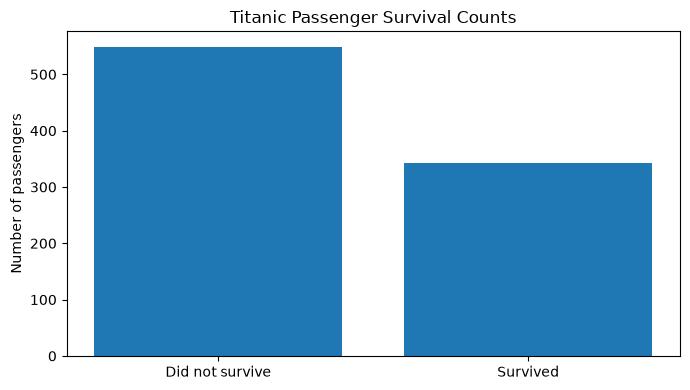

In [3]:
survival_counts = df["Survived"].value_counts().sort_index()
survival_labels = {0: "Did not survive", 1: "Survived"}
survival_summary = survival_counts.rename(index=survival_labels).to_frame("passengers")
survival_summary["percent"] = (survival_summary["passengers"] / len(df) * 100).round(2)
display(survival_summary)

plt.figure(figsize=(7, 4))
plt.bar(["Did not survive", "Survived"], [survival_counts.get(0, 0), survival_counts.get(1, 0)])
plt.title("Titanic Passenger Survival Counts")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.savefig(CHART_DIR / "01_survival_counts.png", dpi=150)
plt.show()


## 4. Survival by sex

,survival_rate,passengers,survival_rate_percent
Sex,,,
female,0.742038,314,74.20
male,0.188908,577,18.89


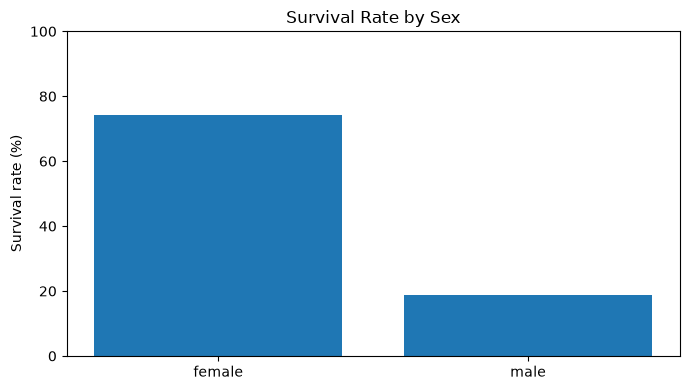

In [4]:
sex_survival = df.groupby("Sex", dropna=False)["Survived"].agg(["mean", "count"]).rename(columns={"mean":"survival_rate","count":"passengers"})
sex_survival["survival_rate_percent"] = (sex_survival["survival_rate"] * 100).round(2)
display(sex_survival)

plot_data = (df.groupby("Sex")["Survived"].mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(7, 4))
plt.bar(plot_data.index.astype(str), plot_data.values)
plt.title("Survival Rate by Sex")
plt.ylabel("Survival rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(CHART_DIR / "02_survival_by_sex.png", dpi=150)
plt.show()


## 5. Survival by passenger class

,survival_rate,passengers,survival_rate_percent
Pclass,,,
1,0.629630,216,62.96
2,0.472826,184,47.28
3,0.242363,491,24.24


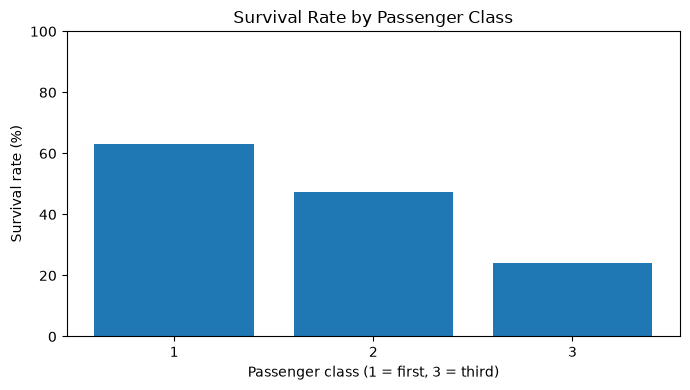

In [5]:
class_survival = df.groupby("Pclass")["Survived"].agg(["mean", "count"]).rename(columns={"mean":"survival_rate","count":"passengers"})
class_survival["survival_rate_percent"] = (class_survival["survival_rate"] * 100).round(2)
display(class_survival)

plot_data = (df.groupby("Pclass")["Survived"].mean() * 100).sort_index()
plt.figure(figsize=(7, 4))
plt.bar(plot_data.index.astype(str), plot_data.values)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger class (1 = first, 3 = third)")
plt.ylabel("Survival rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(CHART_DIR / "03_survival_by_class.png", dpi=150)
plt.show()


## 6. Age distribution

,Age statistics
count,891.000000
mean,29.112424
std,13.304424
min,0.420000
25%,21.500000
50%,26.000000
75%,36.000000
max,80.000000


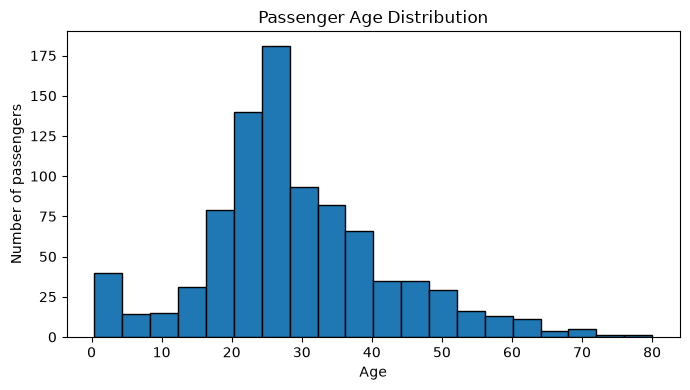

In [6]:
age = pd.to_numeric(df["Age"], errors="coerce").dropna()
display(age.describe().to_frame("Age statistics"))

plt.figure(figsize=(7, 4))
plt.hist(age, bins=20, edgecolor="black")
plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.savefig(CHART_DIR / "04_age_distribution.png", dpi=150)
plt.show()


## 7. Fare distribution and outliers

,Fare statistics
count,891.000000
mean,32.204208
std,49.693429
min,0.000000
25%,7.910400
50%,14.454200
75%,31.000000
max,512.329200


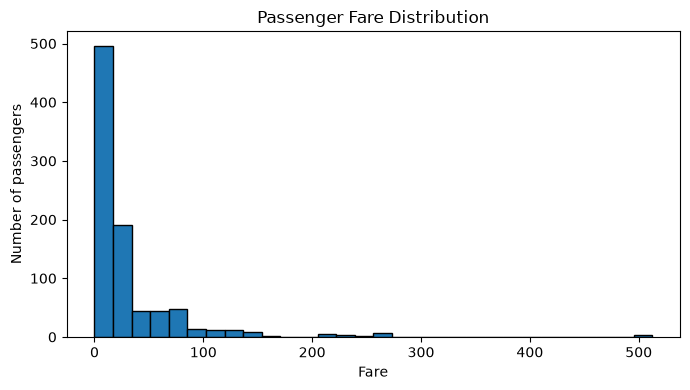

Potential fare outliers by IQR rule: 116
These are potential outliers for investigation, not automatically errors.


In [7]:
fare = pd.to_numeric(df["Fare"], errors="coerce").dropna()
display(fare.describe().to_frame("Fare statistics"))

plt.figure(figsize=(7, 4))
plt.hist(fare, bins=30, edgecolor="black")
plt.title("Passenger Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.savefig(CHART_DIR / "05_fare_distribution.png", dpi=150)
plt.show()

q1, q3 = fare.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
fare_outliers = fare[(fare < lower_bound) | (fare > upper_bound)]
print(f"Potential fare outliers by IQR rule: {len(fare_outliers)}")
print("These are potential outliers for investigation, not automatically errors.")


## 8. Embarkation port and survival

,mean,count,survival_rate_percent
Embarked,,,
C,0.553571,168,55.36
Q,0.389610,77,38.96
S,0.339009,646,33.90


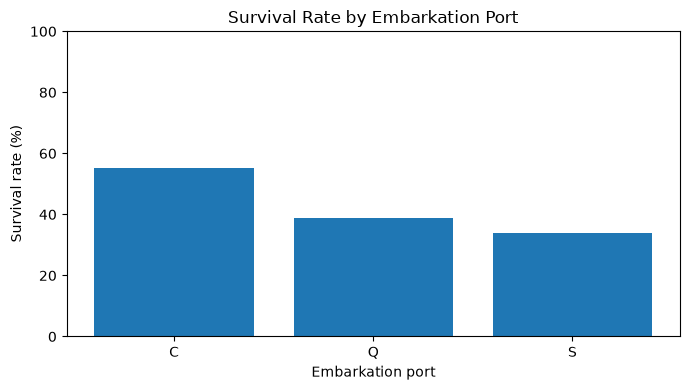

In [8]:
if "Embarked" in df.columns:
    embarked_summary = df.groupby("Embarked")["Survived"].agg(["mean", "count"])
    embarked_summary["survival_rate_percent"] = (embarked_summary["mean"] * 100).round(2)
    display(embarked_summary)

    port_rates = (df.groupby("Embarked")["Survived"].mean() * 100).sort_values(ascending=False)
    plt.figure(figsize=(7, 4))
    plt.bar(port_rates.index.astype(str), port_rates.values)
    plt.title("Survival Rate by Embarkation Port")
    plt.xlabel("Embarkation port")
    plt.ylabel("Survival rate (%)")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.savefig(CHART_DIR / "06_survival_by_embarkation.png", dpi=150)
    plt.show()
else:
    print("Embarked column not found; skipping this analysis.")


## 9. At least five insights from the dataset

In [9]:
# Compute the insights from the loaded data so the statements match the actual dataset.
survival_rate = df["Survived"].mean() * 100
sex_rates = df.groupby("Sex")["Survived"].mean() * 100 if "Sex" in df.columns else pd.Series(dtype=float)
class_rates = df.groupby("Pclass")["Survived"].mean() * 100 if "Pclass" in df.columns else pd.Series(dtype=float)
median_age = df["Age"].median() if "Age" in df.columns else np.nan
median_fare = df["Fare"].median() if "Fare" in df.columns else np.nan
age_missing = df["Age"].isna().sum() if "Age" in df.columns else None
fare_outlier_count = len(fare_outliers) if "Fare" in df.columns else None

insights = [
    f"Overall, {survival_rate:.1f}% of passengers in this dataset survived.",
]
if len(sex_rates):
    highest_sex = sex_rates.idxmax()
    lowest_sex = sex_rates.idxmin()
    insights.append(f"Survival rate differed by sex: {highest_sex} had the highest observed rate ({sex_rates.max():.1f}%), while {lowest_sex} had the lowest ({sex_rates.min():.1f}%).")
if len(class_rates):
    best_class = class_rates.idxmax()
    worst_class = class_rates.idxmin()
    insights.append(f"Passenger class was associated with survival: class {best_class} had the highest rate ({class_rates.max():.1f}%) and class {worst_class} the lowest ({class_rates.min():.1f}%).")
if not pd.isna(median_age):
    insights.append(f"The median passenger age was {median_age:.1f} years.")
if not pd.isna(median_fare):
    insights.append(f"The median recorded fare was {median_fare:.2f}; the fare histogram can be used to examine skew and unusually high fares.")
if fare_outlier_count is not None:
    insights.append(f"The IQR rule flagged {fare_outlier_count} fare values as potential outliers; these should be reviewed rather than automatically deleted.")
if "Embarked" in df.columns and df["Embarked"].notna().any():
    port_rates = df.groupby("Embarked")["Survived"].mean() * 100
    insights.append(f"Observed survival rates also varied by embarkation port; the highest rate in this dataset was for port {port_rates.idxmax()} ({port_rates.max():.1f}%).")

for i, insight in enumerate(insights[:7], start=1):
    print(f"{i}. {insight}")


1. Overall, 38.4% of passengers in this dataset survived.
2. Survival rate differed by sex: female had the highest observed rate (74.2%), while male had the lowest (18.9%).
3. Passenger class was associated with survival: class 1 had the highest rate (63.0%) and class 3 the lowest (24.2%).
4. The median passenger age was 26.0 years.
5. The median recorded fare was 14.45; the fare histogram can be used to examine skew and unusually high fares.
6. The IQR rule flagged 116 fare values as potential outliers; these should be reviewed rather than automatically deleted.
7. Observed survival rates also varied by embarkation port; the highest rate in this dataset was for port C (55.4%).


## 10. Conclusion

The analysis describes survival patterns by sex, passenger class, age, fare, and embarkation port. These are descriptive relationships in the Titanic dataset; they do not prove that any single factor caused survival. The charts are saved to the `charts/` folder.

Before submitting, run all cells, inspect the printed results, and confirm that the notebook completes without errors.
